# Project 4B: Feature Matching for Autostitching

## B.1 Harris Corner Detection

In [3]:
%load_ext autoreload
%autoreload 2
import os, sys
import numpy as np
import matplotlib.pyplot as plt
import skimage.io as skio
%matplotlib inline

PART_A = os.path.abspath("../4a")
if PART_A not in sys.path:
    sys.path.append(PART_A)

from corners import detect_corners, plot_corners

os.makedirs("generated_outputs", exist_ok=True)

SETS = {
    "set1_room":    ("../4a/media/IMG_4479.jpg", "../4a/media/IMG_4480.jpg"),
    "set2_hallway": ("../4a/media/IMG_4484.jpg", "../4a/media/IMG_4485.jpg"),
    "set3_balcony": ("../4a/media/IMG_4486.jpg", "../4a/media/IMG_4487.jpg"),
}
images = {name: (skio.imread(a), skio.imread(b)) for name, (a, b) in SETS.items()}

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


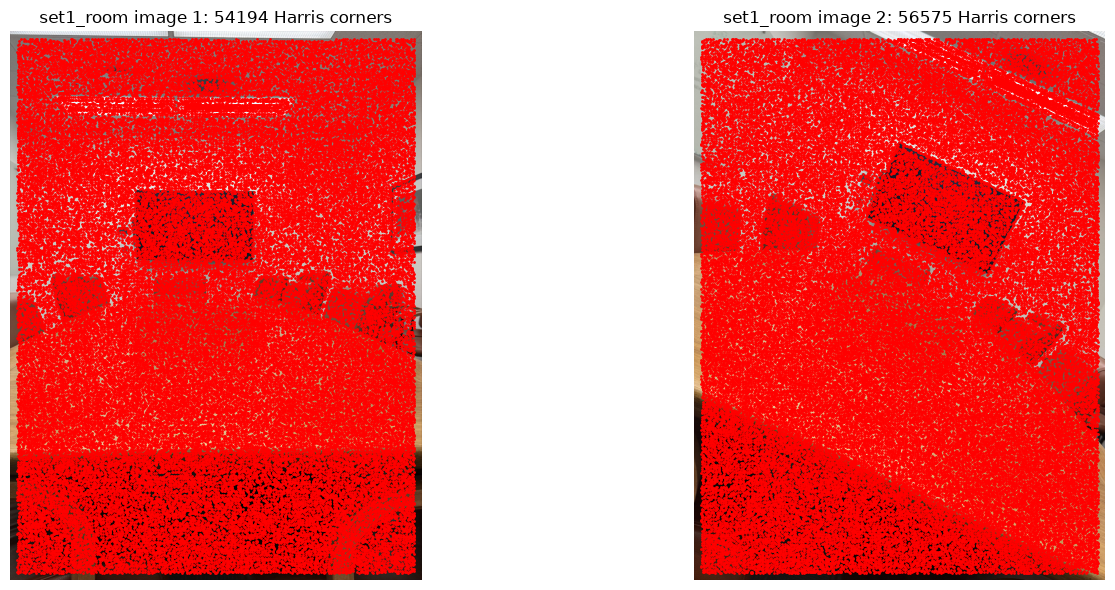

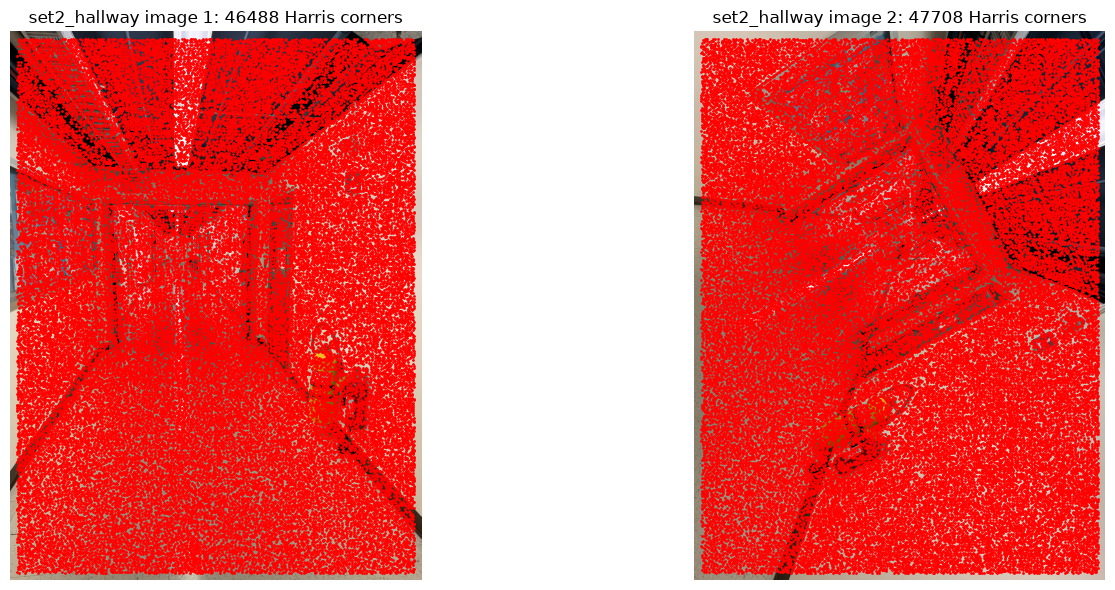

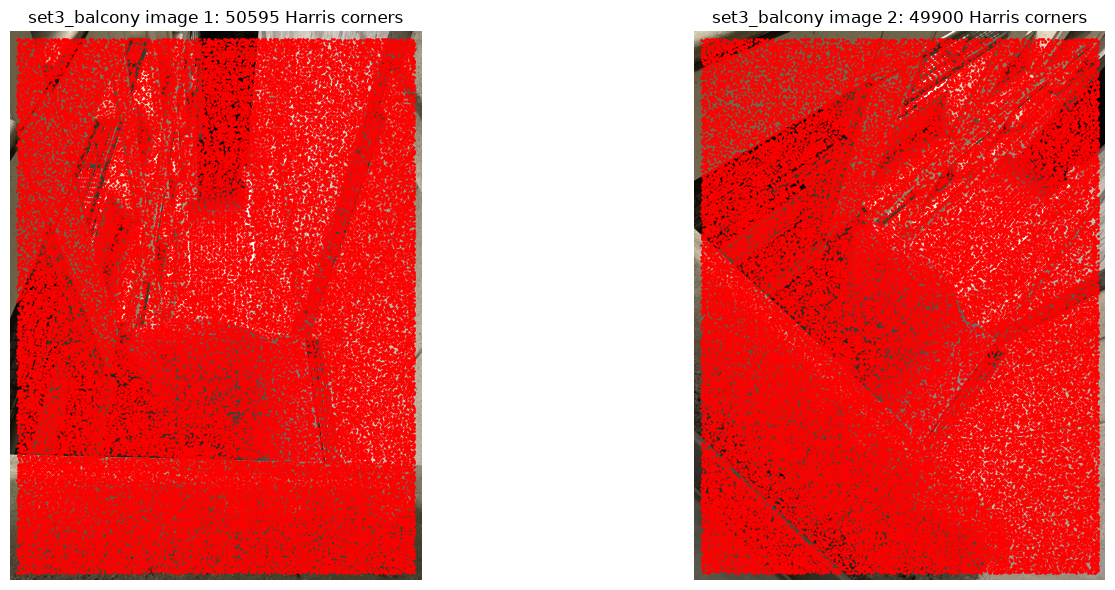

In [4]:
harris = {}
for name, (im1, im2) in images.items():
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    harris[name] = []
    for a,im,k in zip(ax, (im1,im2), (1, 2)):
        h,coords= detect_corners(im)
        harris[name].append((h, coords))
        plot_corners(im, coords, title=f"{name} image {k}: {coords.shape[1]} Harris corners", ax=a)
    plt.tight_layout()
    plt.savefig(f"generated_outputs/b1_harris_{name}.png", bbox_inches="tight", dpi=150)
    plt.show()

### Adaptive Non-Maximal Suppression (ANMS)

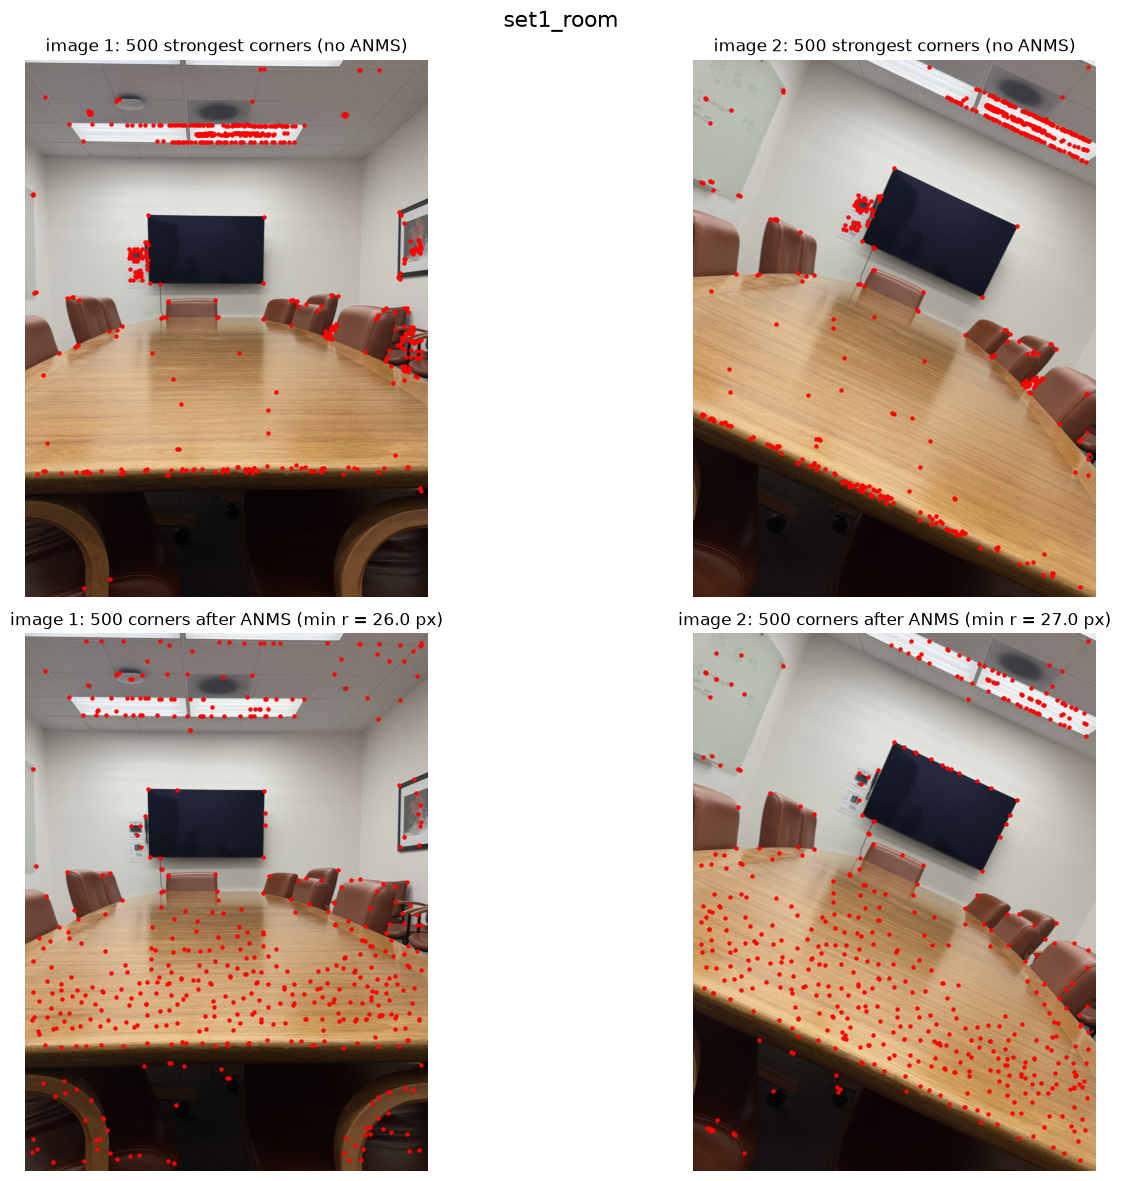

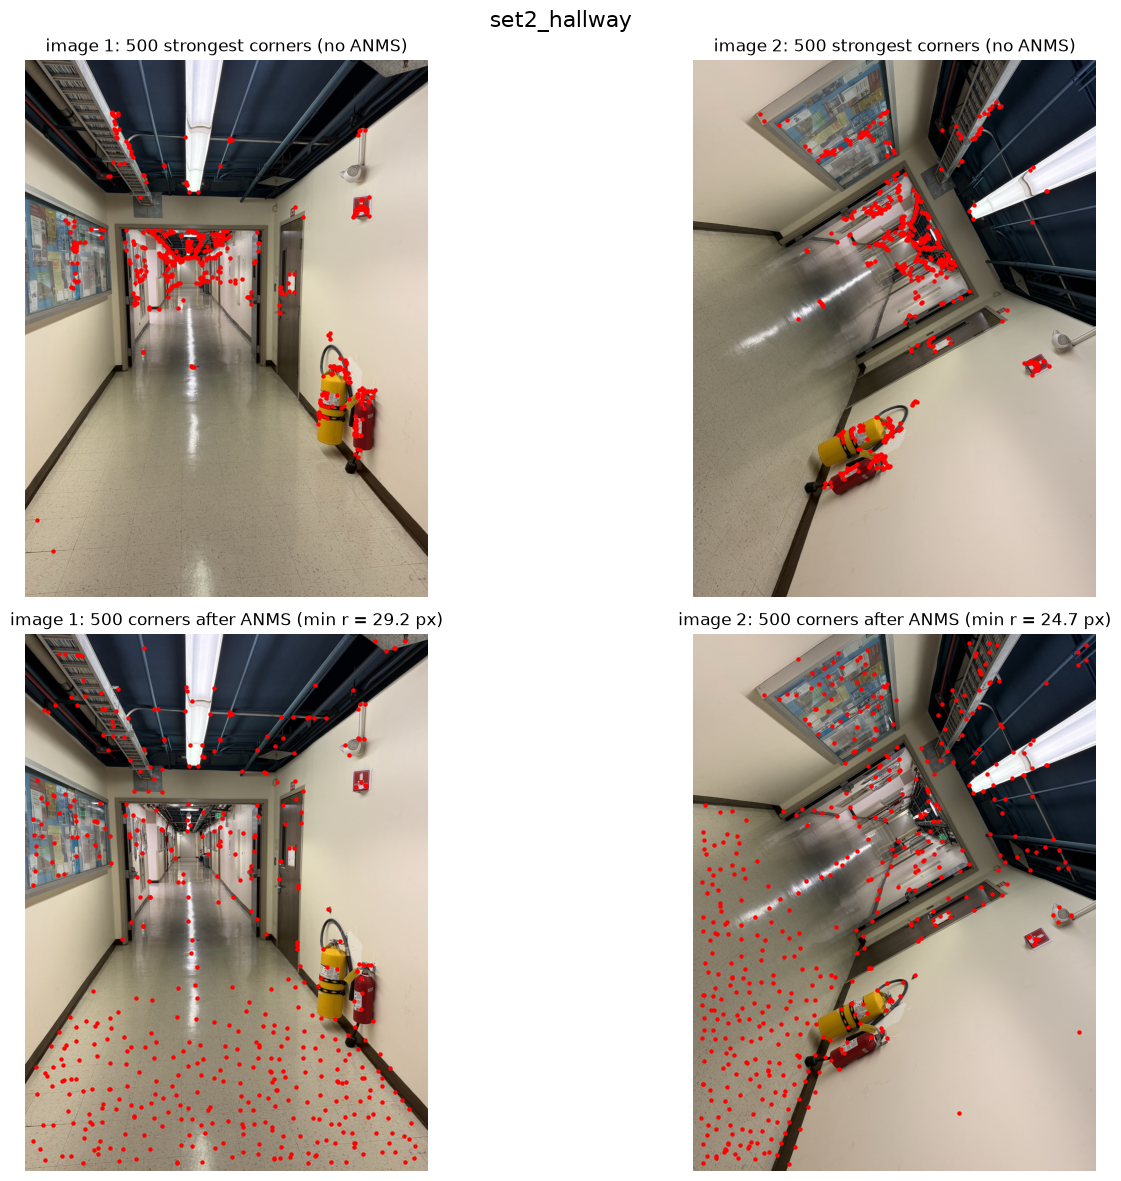

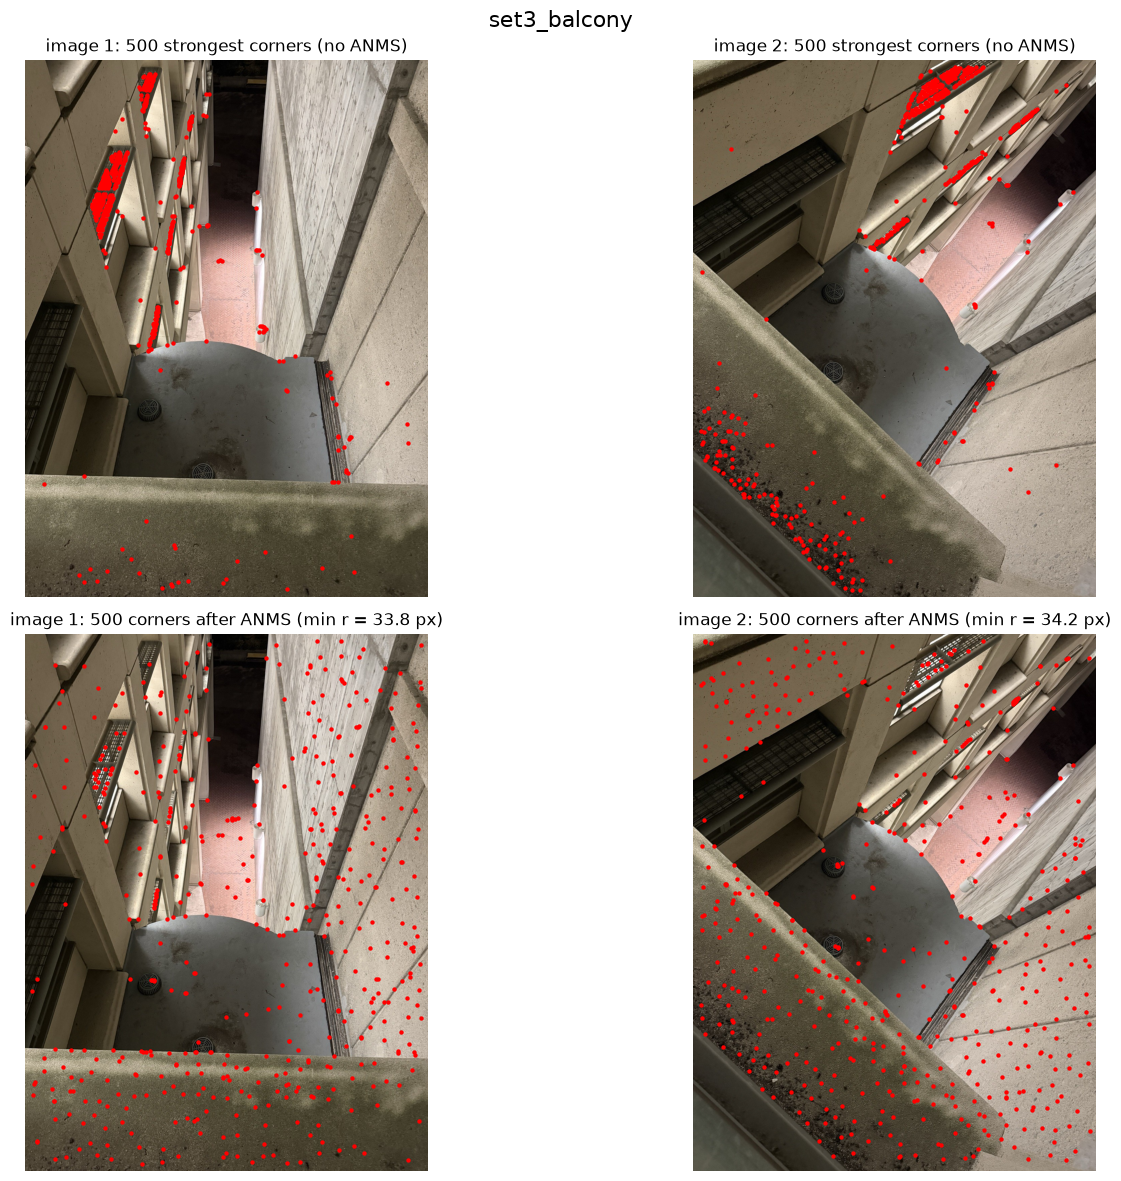

In [5]:
from corners import strongest, anms

N_POINTS = 500

anms_pts = {}
for name, (im1, im2) in images.items():
    fig, ax = plt.subplots(2, 2, figsize=(16, 12))
    anms_pts[name] = []
    for col, (im, (h, coords), k) in enumerate(zip((im1, im2), harris[name], (1, 2))):
        top = strongest(h, coords, N_POINTS)
        pts, radii = anms(h, coords, n_points=N_POINTS)
        anms_pts[name].append(pts)
        plot_corners(im, top, title=f"image {k}: {N_POINTS} strongest corners (no ANMS)", ax=ax[0, col], s=10)
        plot_corners(im, pts, title=f"image {k}: {N_POINTS} corners after ANMS (min r = {radii.min():.1f} px)",
                     ax=ax[1, col], s=10)
    fig.suptitle(name, fontsize=16)
    plt.tight_layout()
    plt.savefig(f"generated_outputs/b1_anms_{name}.png", bbox_inches="tight", dpi=150)
    plt.show()